<a href="https://colab.research.google.com/github/EberHernandezBenitez/Simulacion-II/blob/main/SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo SIR con pyMC

**El modelo SIR** es un sistema de ecuaciones diferenciales utilizado en epidemiología para simular y predecir cómo se propaga una enfermedad infecciosa dentro de una población a lo largo del tiempo.El modelo asume que la población total ($N$) es constante y la divide en tres compartimentos o estados mutuamente excluyentes:

*  **S (Susceptibles)**: Individuos sanos que no tienen la enfermedad y son vulnerales a contraerla.
*   **I (Infectados)**: Individuos que actualmente tienen la enfermedad y pueden transmitirla a los susceptibles.
*   **R (Recuperados o Removidos)**: Individuos que superaron la enfermedad y adquirieron inmunidad permanente, o bien que fallecieron. En ambos casos, ya no pueden infectarse ni contagiar a otros.\

Formulación Matemática:El flujo de personas entre estos tres estados se describe mediante el siguiente sistema de ecuaciones diferenciales ordinarias (EDO) respecto al tiempo ($t$):









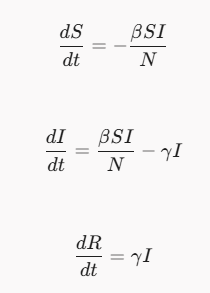

Los parámetros que gobiernan estas tasas de cambio son:$\beta$ (Tasa de transmisión o contacto): Representa la probabilidad de que el contacto entre un individuo susceptible y uno infectado resulte en una nueva infección.$\gamma$ (Tasa de recuperación): Representa la proporción de individuos infectados que se recuperan por unidad de tiempo. Su inverso, $1/\gamma$, equivale al tiempo promedio que una persona es contagiosa.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.optimize import curve_fit

In [3]:
def sir_model(y, t, N, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

In [4]:
# Función envoltorio para el ajustador:
# curve_fit requiere una función donde el primer argumento sea la variable
# independiente (t) y los siguientes sean los parámetros a encontrar.
def fit_odeint(t, beta, gamma):
    N = 1000       # Población total (fija)
    I0, R0 = 1, 0  # Condiciones iniciales (fijas)
    S0 = N - I0 - R0

    # El integrador resuelve las ecuaciones con los parámetros que
    # el optimizador va probando internamente.
    sol = odeint(sir_model, [S0, I0, R0], t, args=(N, beta, gamma))
    return sol[:, 1] # Retornamos solo la columna de Infectados (I)

Parámetros encontrados automáticamente:
Beta:  0.4025
Gamma: 0.1009


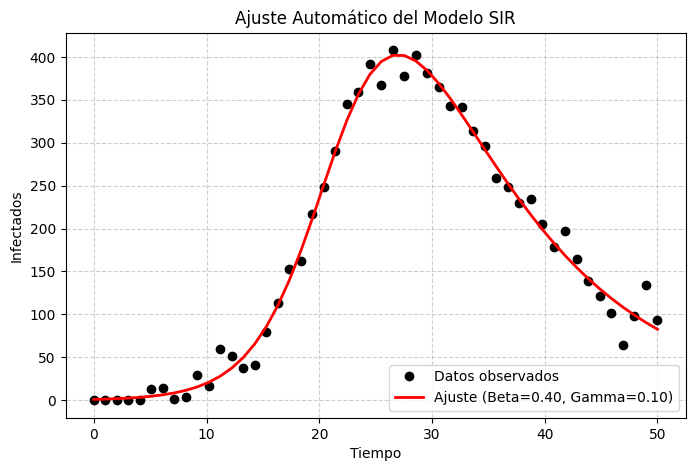

In [6]:
#Datos de prueba simulados
t_data = np.linspace(0, 50, 50)
# Generamos datos sintéticos con ruido para simular observaciones reales
I_reales = fit_odeint(t_data, beta=0.4, gamma=0.1)
y_obs = np.maximum(I_reales + np.random.normal(0, 15, len(t_data)), 0)

#por donde o que valor vamos a iniciar
estimacion_inicial = [0.5, 0.5]

# curve_fit hace todo el trabajo pesado de optimización automáticamente
parametros_optimos, matriz_covarianza = curve_fit(fit_odeint, t_data, y_obs, p0=estimacion_inicial)
beta_opt, gamma_opt = parametros_optimos

print(f"Parámetros encontrados automáticamente:")
print(f"Beta:  {beta_opt:.4f}")
print(f"Gamma: {gamma_opt:.4f}")

#Graficar el resultado
plt.figure(figsize=(8, 5))
plt.plot(t_data, y_obs, 'ko', label='Datos observados')

# Calculamos la curva final usando los parámetros que encontró el optimizador
I_ajustado = fit_odeint(t_data, beta_opt, gamma_opt)
plt.plot(t_data, I_ajustado, 'r-', lw=2, label=f'Ajuste (Beta={beta_opt:.2f}, Gamma={gamma_opt:.2f})')

plt.title('Ajuste Automático del Modelo SIR')
plt.xlabel('Tiempo')
plt.ylabel('Infectados')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()